In [18]:
import pandas as pd
import numpy as np
from google.colab import drive

drive.mount('/content/drive')

# display all columns
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# Set folder path
folder_path = '/content/drive/MyDrive/Fintech Project/'

# Load Fact & Dimension Tables
transactions = pd.read_csv(folder_path + 'transactions.csv')
loans = pd.read_csv(folder_path + 'loans.csv')
accounts = pd.read_csv(folder_path + 'accounts.csv')
customers = pd.read_csv(folder_path + 'customers.csv')
branches = pd.read_csv(folder_path + 'branches.csv')
addresses = pd.read_csv(folder_path + 'addresses.csv')

# Load Reference Tables
customer_types = pd.read_csv(folder_path + 'customer_types.csv')
account_types = pd.read_csv(folder_path + 'account_types.csv')
account_statuses = pd.read_csv(folder_path + 'account_statuses.csv')
transaction_types = pd.read_csv(folder_path + 'transaction_types.csv')
loan_statuses = pd.read_csv(folder_path + 'loan_statuses.csv')

# Verify the shapes
print(f"Transactions Shape: {transactions.shape}")
print(f"Loans Shape:        {loans.shape}")
print(f"Customers Shape:    {customers.shape}")

print(f"accounts Shape:    {accounts.shape}")
print(f"branches Shape:    {branches.shape}")
print(f"addresses Shape:    {addresses.shape}")
print(f"customer types Shape:    {customer_types.shape}")
print(f"account types Shape:    {account_types.shape}")
print(f"account statuses Shape:    {account_statuses.shape}")
print(f"transaction types Shape:    {transaction_types.shape}")
print(f"loan statuses Shape:    {loan_statuses.shape}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Transactions Shape: (50000, 8)
Loans Shape:        (333, 7)
Customers Shape:    (1111, 6)
accounts Shape:    (1667, 6)
branches Shape:    (50, 3)
addresses Shape:    (1222, 4)
customer types Shape:    (3, 2)
account types Shape:    (5, 2)
account statuses Shape:    (3, 2)
transaction types Shape:    (4, 2)
loan statuses Shape:    (3, 2)


In [19]:
# Merge Reference & Dimension Tables into Two main tables Transactions & Loans

# One Big Transactions Table

df_transactions = transactions.merge(transaction_types, on='TransactionTypeID', how='left', suffixes =('_tr','_trty') ).merge(
    branches, on='BranchID', how='left', suffixes=('_tr','_br')).merge(
        accounts, left_on='AccountOriginID', right_on='AccountID', how='left', suffixes=('_tr', '_acc')).merge(
            account_types, on='AccountTypeID', how='left', suffixes=('_tr','_accty')).merge(
                account_statuses, on='AccountStatusID', how='left', suffixes=('_tr','_accst')).merge(
                    customers, on='CustomerID', how='left', suffixes=('_tr','_cst')).merge(
                        customer_types, on='CustomerTypeID', how='left', suffixes=('_tr','_cstty')).merge(
                            addresses, left_on='AddressID_cst',right_on='AddressID', how='left', suffixes=('_tr','_add'))

print(df_transactions.shape)
df_transactions.head(10)

(53653, 29)


,TransactionID,AccountOriginID,AccountDestinationID,TransactionTypeID,Amount,TransactionDate,BranchID,Description,TypeName_tr,BranchName,AddressID_tr,AccountID,CustomerID,AccountTypeID,AccountStatusID,Balance,OpeningDate,TypeName_accty,StatusName,FirstName,LastName,DateOfBirth,AddressID_cst,CustomerTypeID,TypeName,AddressID,Street,City,Country
0,3022681,201164,200868,2,855.17,2023-04-20 02:00:00.000000,41,Transaction 22681,Withdrawal,Branch 41,173,201164,10426,3,1,55889.89,2018-11-14 00:00:00.000000,Payroll,Active,Damion,Compton,1991-07-27 00:00:00.000000,1190,1,Individual,1190,East,Tinley Park,United States
1,3037846,200138,201402,2,806.20,2021-08-10 15:00:00.000000,43,Transaction 37846,Withdrawal,Branch 43,742,200138,10735,1,3,35239.90,2019-03-04 00:00:00.000000,Checking,Closed,Jonas,Santiago,1996-01-06 00:00:00.000000,1015,3,Large Enterprise,1015,Felton,Camas,United States
2,3045293,201002,201180,1,1229.44,2020-08-16 03:00:00.000000,5,Transaction 45293,Deposit,Branch 5,796,201002,10458,3,1,92795.90,2020-09-20 00:00:00.000000,Payroll,Active,Belkis,Trevino,1994-05-13 00:00:00.000000,832,2,Small Business,832,Waller,Mount Pleasant,United States
3,3017397,201066,201144,4,4441.60,2021-10-10 06:00:00.000000,14,Transaction 17397,Payment,Branch 14,491,201066,10557,1,1,48854.26,2020-12-30 00:00:00.000000,Checking,Active,Loyd,Baird,1963-02-04 00:00:00.000000,47,2,Small Business,47,Thomas,Walnut,United States
4,3016750,200289,201413,3,2526.20,2022-07-28 00:00:00.000000,37,Transaction 16750,Transfer,Branch 37,265,200289,10699,4,1,59032.48,2018-11-13 00:00:00.000000,Business,Active,Claudio,NaN,1983-10-15 00:00:00.000000,614,2,Small Business,614,Rodriguez,Rocklin,United States
5,3020141,200144,200319,3,1498.48,2023-07-08 13:00:00.000000,20,Transaction 20141,Transfer,Branch 20,665,200144,10798,1,1,46961.82,2019-08-07 00:00:00.000000,Checking,Active,Virgilio,Singleton,1999-07-14 00:00:00.000000,299,3,Large Enterprise,299,Sickles,NaN,United States
6,3039836,201137,200095,1,2556.13,2021-09-03 01:00:00.000000,34,Transaction 39836,Deposit,Branch 34,986,201137,10436,3,1,73446.68,2021-06-22 00:00:00.000000,Payroll,Active,Chantell,Schneider,1993-01-03 00:00:00.000000,268,3,Large Enterprise,268,Bigler,Medina,United States
7,3018170,201594,200292,2,2321.85,2021-07-18 21:00:00.000000,14,Transaction 18170,Withdrawal,Branch 14,491,201594,10035,2,1,99358.56,2019-06-09 00:00:00.000000,Savings,Active,Dierdre,Bird,1962-04-10 00:00:00.000000,965,3,Large Enterprise,965,Avenue F,Atlantic City,United States
8,3048888,201340,200210,3,1649.81,2022-06-04 01:00:00.000000,50,Transaction 48888,Transfer,Branch 50,22,201340,10481,5,1,12603.53,2019-02-18 00:00:00.000000,Youth,Active,Jewell,Richmond,1961-02-25 00:00:00.000000,536,3,Large Enterprise,536,Beeman,Hinsdale,United States
9,3048575,200503,201417,1,632.38,2021-02-22 19:00:00.000000,22,Transaction 48575,Deposit,Branch 22,1155,200503,10109,5,1,60628.55,NaN,Youth,Active,Isidro,Wells,1978-06-23 00:00:00.000000,411,2,Small Business,411,NaN,Munster,United States


In [20]:
accounts.head()

,AccountID,CustomerID,AccountTypeID,AccountStatusID,Balance,OpeningDate
0,200094,10123,3,1,48348.54,2018-06-12 00:00:00.000000
1,201108,10077,3,1,35001.41,2019-10-30 00:00:00.000000
2,201453,10321,3,2,57081.03,2020-05-24 00:00:00.000000
3,200581,10871,5,1,63164.33,2021-01-27 00:00:00.000000
4,200003,10765,1,1,58739.64,2018-09-12 00:00:00.000000


In [21]:
# One Big Loans Table

df_loans = loans.merge(loan_statuses, on='LoanStatusID' , how='left', suffixes=('_lo','_lost')).merge(
    accounts, on='AccountID', how='left', suffixes=('_lo','_acc')).merge(
            account_types, on='AccountTypeID', how='left', suffixes=('_lo','_accty')).merge(
                account_statuses, on='AccountStatusID', how='left', suffixes=('_lo','_accst')).merge(
    customers, on='CustomerID', how='left', suffixes=('_lo','_cst')).merge(
        customer_types, on='CustomerTypeID', how='left', suffixes=('_lo','_cstty'))

print(df_loans.shape)
df_loans.head(10)

(342, 21)


,LoanID,AccountID,LoanStatusID,PrincipalAmount,InterestRate,StartDate,EstimatedEndDate,StatusName_lo,CustomerID,AccountTypeID,AccountStatusID,Balance,OpeningDate,TypeName_lo,StatusName_accst,FirstName,LastName,DateOfBirth,AddressID,CustomerTypeID,TypeName_cstty
0,400230,200876,1,76958.56,0.0547,2022-11-20 00:00:00.000000,2026-08-06 00:00:00.000000,Active,10230,1,1,32788.26,2020-12-24 00:00:00.000000,Checking,Active,Janita,Lucas,1967-09-09 00:00:00.000000,578,3,Large Enterprise
1,400307,200789,1,29013.67,0.0321,2022-02-22 00:00:00.000000,2025-12-08 00:00:00.000000,Active,10579,5,1,39031.96,2020-06-20 00:00:00.000000,Youth,Active,Hong,Carson,1970-03-20 00:00:00.000000,658,1,Individual
2,400233,201275,1,48596.76,0.1017,2021-11-21 00:00:00.000000,2023-07-30 00:00:00.000000,Active,10505,5,1,55584.89,2019-03-13 00:00:00.000000,Youth,Active,Audrie,Juarez,NaT,779,1,Individual
3,400100,200070,1,9191.43,0.0999,2021-08-14 00:00:00.000000,2023-09-18 00:00:00.000000,Active,10632,5,1,57405.83,NaN,Youth,Active,Kenton,Francis,1998-09-08 00:00:00.000000,1209,3,Large Enterprise
4,400141,200808,1,76322.83,0.0906,2021-06-04 00:00:00.000000,2024-10-23 00:00:00.000000,Active,10795,3,1,69814.18,2020-05-03 00:00:00.000000,Payroll,Active,Damion,Montgomery,1987-07-08 00:00:00.000000,950,1,Individual
5,400320,201246,2,93715.10,0.0784,2022-03-09 00:00:00.000000,2025-12-28 00:00:00.000000,Paid Off,10667,2,2,4676.32,2018-05-17 00:00:00.000000,Savings,Inactive,Rudy,Waller,1984-01-02 00:00:00.000000,322,1,Individual
6,400267,200148,1,19627.15,0.0864,2021-06-29 00:00:00.000000,2024-07-25 00:00:00.000000,Active,10680,2,1,19169.97,2019-01-08 00:00:00.000000,Savings,Active,Audria,Larsen,1989-11-07 00:00:00.000000,301,1,Individual
7,400317,201509,2,40473.32,0.1276,2022-01-21 00:00:00.000000,2025-04-30 00:00:00.000000,Paid Off,11090,3,1,51630.82,2019-08-08 00:00:00.000000,Payroll,Active,Codi,Nunez,1982-02-24 00:00:00.000000,867,2,Small Business
8,400323,200934,1,41206.98,0.1411,2021-09-14 00:00:00.000000,2023-11-18 00:00:00.000000,Active,10631,5,1,5803.63,2019-08-19 00:00:00.000000,Youth,Active,Eddy,Tran,1969-11-25 00:00:00.000000,906,2,Small Business
9,400034,200404,1,97362.97,0.1145,2023-02-02 00:00:00.000000,2027-01-11 00:00:00.000000,Active,10229,3,1,32623.75,2021-12-24 00:00:00.000000,Payroll,Active,Myles,Watson,1971-05-18 00:00:00.000000,545,3,Large Enterprise


In [22]:
def audit_dataset(df, name="Dataset"):
    print(f"\n==========================================")
    print(f"     DATA QUALITY AUDIT: {name}")
    print(f"==========================================")
    print(f"Total Rows:    {len(df):,}")
    print(f"Total Columns: {df.shape[1]}")
    print(f"Duplicates:    {df.duplicated().sum()}")

    missing = df.isnull().sum()
    missing_pct = (missing / len(df)) * 100
    missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct.round(2)})
    missing_df = missing_df[missing_df['Missing Count'] > 0]

    print("\n--- Missing Value Report ---")
    if len(missing_df) > 0:
        print(missing_df)
    else:
        print("No missing values detected!")

audit_dataset(df_transactions, "Transactions")
audit_dataset(df_loans, "Loans")


     DATA QUALITY AUDIT: Transactions
Total Rows:    53,653
Total Columns: 29
Duplicates:    4153

--- Missing Value Report ---
                 Missing Count  Missing %
TransactionDate           1076       2.01
OpeningDate               1115       2.08
FirstName                  810       1.51
LastName                   943       1.76
Street                     740       1.38
City                      1203       2.24
Country                   1195       2.23

     DATA QUALITY AUDIT: Loans
Total Rows:    342
Total Columns: 21
Duplicates:    12

--- Missing Value Report ---
                  Missing Count  Missing %
StartDate                     6       1.75
EstimatedEndDate              6       1.75
OpeningDate                  12       3.51
FirstName                     8       2.34
LastName                      4       1.17


In [23]:
# Coverting date columns from object to datetime

date_cols = [
    col for col in df_transactions.columns
    if 'date' in col.lower() or 'time' in col.lower()
]

for col in date_cols:
    df_transactions[col] = pd.to_datetime(df_transactions[col], errors='coerce')

df_transactions.dtypes

,0
TransactionID,int64
AccountOriginID,int64
AccountDestinationID,int64
TransactionTypeID,int64
Amount,float64
TransactionDate,datetime64[ns]
BranchID,int64
Description,object
TypeName_tr,object
BranchName,object


In [24]:
df_transactions.describe()

,TransactionID,AccountOriginID,AccountDestinationID,TransactionTypeID,Amount,TransactionDate,BranchID,AddressID_tr,AccountID,CustomerID,AccountTypeID,AccountStatusID,Balance,OpeningDate,DateOfBirth,AddressID_cst,CustomerTypeID,AddressID
count,5.365300e+04,53653.000000,53653.000000,53653.000000,53653.000000,52577,53653.000000,53653.000000,53653.000000,53653.000000,53653.000000,53653.000000,53653.000000,52538,51957,53653.000000,53653.000000,53653.000000
mean,3.024751e+06,200819.181891,200820.169366,2.192422,2504.568475,2022-02-02 04:11:47.855518208,25.615063,539.963599,200819.181891,10556.105959,3.048571,1.242764,48894.920088,2020-02-01 23:19:56.630419968,1981-02-17 16:01:51.090523968,636.031182,2.066893,636.031182
min,3.000000e+06,200000.000000,200000.000000,1.000000,1.010000,2020-01-01 00:00:00,1.000000,21.000000,200000.000000,10000.000000,1.000000,1.000000,-486.680000,2018-01-03 00:00:00,1960-01-27 00:00:00,3.000000,1.000000,3.000000
25%,3.012397e+06,200410.000000,200407.000000,1.000000,1262.570000,2021-01-09 22:00:00,13.000000,199.000000,200410.000000,10297.000000,2.000000,1.000000,23213.220000,2019-01-18 00:00:00,1969-10-01 00:00:00,358.000000,1.000000,358.000000
50%,3.024727e+06,200808.000000,200816.000000,2.000000,2506.520000,2022-01-25 16:00:00,26.000000,551.000000,200808.000000,10552.000000,3.000000,1.000000,49200.390000,2020-01-17 00:00:00,1981-03-20 00:00:00,643.000000,2.000000,643.000000
75%,3.037135e+06,201235.000000,201232.000000,3.000000,3755.050000,2023-02-05 09:00:00,38.000000,796.000000,201235.000000,10830.000000,4.000000,1.000000,74503.830000,2021-01-26 00:00:00,1992-03-20 00:00:00,927.000000,3.000000,927.000000
max,3.049499e+06,201650.000000,201650.000000,4.000000,4999.590000,2026-08-28 15:01:43.084879,50.000000,1210.000000,201650.000000,11099.000000,5.000000,3.000000,99828.980000,2026-07-06 15:01:42.900415,2026-07-06 15:01:42.854835,1210.000000,3.000000,1210.000000
std,1.428255e+04,478.090132,476.737877,0.982223,1442.758702,NaN,14.479273,360.965120,478.090132,313.693326,1.407035,0.527712,29092.862727,NaN,NaN,339.272359,0.818513,339.272359


In [25]:
# Cleaning Data

#Clean_df_transactions

# Making a Copy to work on
clean_df_transactions = df_transactions.copy()

# Removing Duplicates
duplicate_count = df_transactions.duplicated().sum()
if duplicate_count > 0:
  clean_df_transactions = df_transactions.drop_duplicates()
else:
  clean_df_transactions


#Renaming Columns
clean_df_transactions = clean_df_transactions.rename(columns={'TypeName_tr' : 'Transaction_Type', 'TypeName_accty' : 'Account_Type'
, 'TypeName' : 'Customer_Type'})


clean_df_transactions

,TransactionID,AccountOriginID,AccountDestinationID,TransactionTypeID,Amount,TransactionDate,BranchID,Description,Transaction_Type,BranchName,AddressID_tr,AccountID,CustomerID,AccountTypeID,AccountStatusID,Balance,OpeningDate,Account_Type,StatusName,FirstName,LastName,DateOfBirth,AddressID_cst,CustomerTypeID,Customer_Type,AddressID,Street,City,Country
0,3022681,201164,200868,2,855.17,2023-04-20 02:00:00,41,Transaction 22681,Withdrawal,Branch 41,173,201164,10426,3,1,55889.89,2018-11-14,Payroll,Active,Damion,Compton,1991-07-27,1190,1,Individual,1190,East,Tinley Park,United States
1,3037846,200138,201402,2,806.20,2021-08-10 15:00:00,43,Transaction 37846,Withdrawal,Branch 43,742,200138,10735,1,3,35239.90,2019-03-04,Checking,Closed,Jonas,Santiago,1996-01-06,1015,3,Large Enterprise,1015,Felton,Camas,United States
2,3045293,201002,201180,1,1229.44,2020-08-16 03:00:00,5,Transaction 45293,Deposit,Branch 5,796,201002,10458,3,1,92795.90,2020-09-20,Payroll,Active,Belkis,Trevino,1994-05-13,832,2,Small Business,832,Waller,Mount Pleasant,United States
3,3017397,201066,201144,4,4441.60,2021-10-10 06:00:00,14,Transaction 17397,Payment,Branch 14,491,201066,10557,1,1,48854.26,2020-12-30,Checking,Active,Loyd,Baird,1963-02-04,47,2,Small Business,47,Thomas,Walnut,United States
4,3016750,200289,201413,3,2526.20,2022-07-28 00:00:00,37,Transaction 16750,Transfer,Branch 37,265,200289,10699,4,1,59032.48,2018-11-13,Business,Active,Claudio,NaN,1983-10-15,614,2,Small Business,614,Rodriguez,Rocklin,United States
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
53647,3028048,200640,201374,2,2486.96,2023-11-04 23:00:00,2,Transaction 28048,Withdrawal,Branch 2,511,200640,10570,2,1,41593.86,2019-01-12,Savings,Active,Michale,Duffy,1966-09-11,683,1,Individual,683,Battery Blaney,Louisville,United States
53648,3006284,200709,200667,4,3978.09,2022-06-03 02:00:00,11,Transaction 6284,Payment,Branch 11,30,200709,10335,1,1,60544.65,2019-06-16,Checking,Active,Brandon,Mayo,1963-10-14,381,2,Small Business,381,Sunset,Trussville,United States
53649,3028219,200513,200603,1,1507.27,2021-11-18 12:00:00,3,Transaction 28219,Deposit,Branch 3,27,200513,10997,3,2,76110.76,2020-08-31,Payroll,Inactive,Mila,Espinoza,1961-05-05,206,3,Large Enterprise,206,Wiese,Mount Pleasant,United States
53651,3009955,200045,200942,4,4242.71,2020-06-20 09:00:00,24,Transaction 9955,Payment,Branch 24,1210,200045,11018,3,2,52907.30,2019-06-12,Payroll,Inactive,Katherina,Woods,1980-11-14,29,3,Large Enterprise,29,Walter U Lum,Central Point,United States


In [26]:
# Fulfilling Null values within text columns with 'Unknown'
nulls_To_fill = ['FirstName','LastName','Street','City','Country']
for col in nulls_To_fill:
  if col in clean_df_transactions.columns:
    clean_df_transactions[col] =  clean_df_transactions[col].fillna('Unknown')


clean_df_transactions

,TransactionID,AccountOriginID,AccountDestinationID,TransactionTypeID,Amount,TransactionDate,BranchID,Description,Transaction_Type,BranchName,AddressID_tr,AccountID,CustomerID,AccountTypeID,AccountStatusID,Balance,OpeningDate,Account_Type,StatusName,FirstName,LastName,DateOfBirth,AddressID_cst,CustomerTypeID,Customer_Type,AddressID,Street,City,Country
0,3022681,201164,200868,2,855.17,2023-04-20 02:00:00,41,Transaction 22681,Withdrawal,Branch 41,173,201164,10426,3,1,55889.89,2018-11-14,Payroll,Active,Damion,Compton,1991-07-27,1190,1,Individual,1190,East,Tinley Park,United States
1,3037846,200138,201402,2,806.20,2021-08-10 15:00:00,43,Transaction 37846,Withdrawal,Branch 43,742,200138,10735,1,3,35239.90,2019-03-04,Checking,Closed,Jonas,Santiago,1996-01-06,1015,3,Large Enterprise,1015,Felton,Camas,United States
2,3045293,201002,201180,1,1229.44,2020-08-16 03:00:00,5,Transaction 45293,Deposit,Branch 5,796,201002,10458,3,1,92795.90,2020-09-20,Payroll,Active,Belkis,Trevino,1994-05-13,832,2,Small Business,832,Waller,Mount Pleasant,United States
3,3017397,201066,201144,4,4441.60,2021-10-10 06:00:00,14,Transaction 17397,Payment,Branch 14,491,201066,10557,1,1,48854.26,2020-12-30,Checking,Active,Loyd,Baird,1963-02-04,47,2,Small Business,47,Thomas,Walnut,United States
4,3016750,200289,201413,3,2526.20,2022-07-28 00:00:00,37,Transaction 16750,Transfer,Branch 37,265,200289,10699,4,1,59032.48,2018-11-13,Business,Active,Claudio,Unknown,1983-10-15,614,2,Small Business,614,Rodriguez,Rocklin,United States
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
53647,3028048,200640,201374,2,2486.96,2023-11-04 23:00:00,2,Transaction 28048,Withdrawal,Branch 2,511,200640,10570,2,1,41593.86,2019-01-12,Savings,Active,Michale,Duffy,1966-09-11,683,1,Individual,683,Battery Blaney,Louisville,United States
53648,3006284,200709,200667,4,3978.09,2022-06-03 02:00:00,11,Transaction 6284,Payment,Branch 11,30,200709,10335,1,1,60544.65,2019-06-16,Checking,Active,Brandon,Mayo,1963-10-14,381,2,Small Business,381,Sunset,Trussville,United States
53649,3028219,200513,200603,1,1507.27,2021-11-18 12:00:00,3,Transaction 28219,Deposit,Branch 3,27,200513,10997,3,2,76110.76,2020-08-31,Payroll,Inactive,Mila,Espinoza,1961-05-05,206,3,Large Enterprise,206,Wiese,Mount Pleasant,United States
53651,3009955,200045,200942,4,4242.71,2020-06-20 09:00:00,24,Transaction 9955,Payment,Branch 24,1210,200045,11018,3,2,52907.30,2019-06-12,Payroll,Inactive,Katherina,Woods,1980-11-14,29,3,Large Enterprise,29,Walter U Lum,Central Point,United States


In [27]:
#dropping TransactionDate Null Values Rows

clean_df_transactions = clean_df_transactions.dropna(subset=['TransactionDate'])

clean_df_transactions

,TransactionID,AccountOriginID,AccountDestinationID,TransactionTypeID,Amount,TransactionDate,BranchID,Description,Transaction_Type,BranchName,AddressID_tr,AccountID,CustomerID,AccountTypeID,AccountStatusID,Balance,OpeningDate,Account_Type,StatusName,FirstName,LastName,DateOfBirth,AddressID_cst,CustomerTypeID,Customer_Type,AddressID,Street,City,Country
0,3022681,201164,200868,2,855.17,2023-04-20 02:00:00,41,Transaction 22681,Withdrawal,Branch 41,173,201164,10426,3,1,55889.89,2018-11-14,Payroll,Active,Damion,Compton,1991-07-27,1190,1,Individual,1190,East,Tinley Park,United States
1,3037846,200138,201402,2,806.20,2021-08-10 15:00:00,43,Transaction 37846,Withdrawal,Branch 43,742,200138,10735,1,3,35239.90,2019-03-04,Checking,Closed,Jonas,Santiago,1996-01-06,1015,3,Large Enterprise,1015,Felton,Camas,United States
2,3045293,201002,201180,1,1229.44,2020-08-16 03:00:00,5,Transaction 45293,Deposit,Branch 5,796,201002,10458,3,1,92795.90,2020-09-20,Payroll,Active,Belkis,Trevino,1994-05-13,832,2,Small Business,832,Waller,Mount Pleasant,United States
3,3017397,201066,201144,4,4441.60,2021-10-10 06:00:00,14,Transaction 17397,Payment,Branch 14,491,201066,10557,1,1,48854.26,2020-12-30,Checking,Active,Loyd,Baird,1963-02-04,47,2,Small Business,47,Thomas,Walnut,United States
4,3016750,200289,201413,3,2526.20,2022-07-28 00:00:00,37,Transaction 16750,Transfer,Branch 37,265,200289,10699,4,1,59032.48,2018-11-13,Business,Active,Claudio,Unknown,1983-10-15,614,2,Small Business,614,Rodriguez,Rocklin,United States
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
53646,3030796,200162,200716,2,518.49,2021-10-13 06:00:00,41,Transaction 30796,Withdrawal,Branch 41,173,200162,10504,5,1,13680.97,2018-04-19,Youth,Active,Victor,Barry,1960-03-14,928,1,Individual,928,Saroyan,Grayslake,United States
53647,3028048,200640,201374,2,2486.96,2023-11-04 23:00:00,2,Transaction 28048,Withdrawal,Branch 2,511,200640,10570,2,1,41593.86,2019-01-12,Savings,Active,Michale,Duffy,1966-09-11,683,1,Individual,683,Battery Blaney,Louisville,United States
53648,3006284,200709,200667,4,3978.09,2022-06-03 02:00:00,11,Transaction 6284,Payment,Branch 11,30,200709,10335,1,1,60544.65,2019-06-16,Checking,Active,Brandon,Mayo,1963-10-14,381,2,Small Business,381,Sunset,Trussville,United States
53649,3028219,200513,200603,1,1507.27,2021-11-18 12:00:00,3,Transaction 28219,Deposit,Branch 3,27,200513,10997,3,2,76110.76,2020-08-31,Payroll,Inactive,Mila,Espinoza,1961-05-05,206,3,Large Enterprise,206,Wiese,Mount Pleasant,United States


In [28]:
#clean_df_transactions.isnull().sum()[clean_df_transactions.isnull().sum() > 0]


In [29]:
#clean_df_transactions[clean_df_transactions['TransactionDate'].isnull() == True]

In [34]:
# Creating new columns using dates for upcoming analysis

# Calculating Customer age
today = pd.to_datetime('today')
clean_df_transactions.loc[:,'age'] = round((today - clean_df_transactions['DateOfBirth']).dt.days/365)

# Creating year, month and weekday from TransactionDate
clean_df_transactions.loc[:,'transaction_year'] = clean_df_transactions['TransactionDate'].dt.year

clean_df_transactions.loc[:,'transaction_hour'] = clean_df_transactions['TransactionDate'].dt.hour

clean_df_transactions.loc[:,'transaction_month'] = clean_df_transactions['TransactionDate'].dt.to_period('M')

# DOW = Day OF Week
clean_df_transactions.loc[:,'transaction_dow'] = clean_df_transactions['TransactionDate'].dt.day_name()

clean_df_transactions['transaction_hour']


,transaction_hour
0,2
1,15
2,3
3,6
4,0
...,...
53646,6
53647,23
53648,2
53649,12


In [31]:
# Checking Transaction Amount Negative Value

clean_df_transactions['Amount'].describe()

clean_df_transactions[clean_df_transactions['Amount'] <= 0]


,TransactionID,AccountOriginID,AccountDestinationID,TransactionTypeID,Amount,TransactionDate,BranchID,Description,Transaction_Type,BranchName,AddressID_tr,AccountID,CustomerID,AccountTypeID,AccountStatusID,Balance,OpeningDate,Account_Type,StatusName,FirstName,LastName,DateOfBirth,AddressID_cst,CustomerTypeID,Customer_Type,AddressID,Street,City,Country,age,transaction_year,transaction_hour,transaction_month,transaction_dow


In [32]:
# Detecting Outliers using Interquartile Range Method (Outliers should be less than lower bound or greater than upper bound)
Q1 = clean_df_transactions['Amount'].quantile(.25)
Q3 = clean_df_transactions['Amount'].quantile(.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

IQR_outliers = clean_df_transactions[(clean_df_transactions['Amount'] < lower_bound) | (clean_df_transactions['Amount'] > upper_bound)]

IQR_outliers

,TransactionID,AccountOriginID,AccountDestinationID,TransactionTypeID,Amount,TransactionDate,BranchID,Description,Transaction_Type,BranchName,AddressID_tr,AccountID,CustomerID,AccountTypeID,AccountStatusID,Balance,OpeningDate,Account_Type,StatusName,FirstName,LastName,DateOfBirth,AddressID_cst,CustomerTypeID,Customer_Type,AddressID,Street,City,Country,age,transaction_year,transaction_hour,transaction_month,transaction_dow


In [155]:
# Calculate Overall KPIs
total_transactions = clean_df_transactions['TransactionID'].nunique()
total_amount = clean_df_transactions['Amount'].sum()
total_accounts = clean_df_transactions['AccountID'].nunique()
total_customers = clean_df_transactions['CustomerID'].nunique()

print(f"Total_Transactions : {total_transactions:,}")
print(f"Total amount : {total_amount:,}")
print(f"Total accounts : {total_accounts:,}")
print(f"Total customers : {total_customers:,}")

# Breakdown by Transaction Type

per_transaction_type = clean_df_transactions.groupby('Transaction_Type').agg(
    total_transactions = ('TransactionID','nunique'),
    total_amount = ('Amount','sum'),
    total_accounts = ('AccountID','nunique'),
    total_customers = ('CustomerID','nunique')
).reset_index()

per_transaction_type['Amount_Contribution_per_type'] = (per_transaction_type['total_amount'] / total_amount) * 100

print("Portfolio Performance Per Transaction Type")
display(per_transaction_type)


Total_Transactions : 48,510
Total amount : 121,483,318.66
Total accounts : 1,651
Total customers : 862
Portfolio Performance Per Transaction Type


,Transaction_Type,total_transactions,total_amount,total_accounts,total_customers,Amount_Contribution_per_type
0,Deposit,14760,36923620.63,1651,862,30.393984
1,Payment,4860,12147849.51,1551,839,9.999603
2,Transfer,14478,36439662.92,1651,862,29.995610
3,Withdrawal,14412,35972185.60,1651,862,29.610803


In [165]:
# Checking transactions movement between different accounts' statuses

per_account_status = clean_df_transactions.groupby('StatusName').agg(
    total_transactions = ('TransactionID','nunique'),
    total_amount = ('Amount','sum'),
    avg_amount=('Amount', 'mean'),
    total_accounts = ('AccountID','nunique'),
    total_customers = ('CustomerID','nunique')
).reset_index()

total_amount = clean_df_transactions['Amount'].sum()

per_account_status['Amount_Contribution_per_status'] = (per_account_status['total_amount'] / total_amount) * 100

print("Account Status Risk Analysis")
display(per_account_status)

Account Status Risk Analysis


,StatusName,total_transactions,total_amount,avg_amount,total_accounts,total_customers,Amount_Contribution_per_status
0,Active,39023,97659004.52,2502.601146,1327,770,80.388818
1,Closed,2206,5526486.43,2505.206904,74,72,4.549173
2,Inactive,7281,18297827.71,2513.092667,250,221,15.062008


In [193]:
# Hours Analysis

per_hour = clean_df_transactions.groupby(['transaction_year', 'transaction_hour']).agg(
    total_transactions = ('TransactionID','nunique'),
    total_amount = ('Amount','sum'),
    avg_amount=('Amount', 'mean'),
    total_accounts = ('AccountID','nunique'),
    total_customers = ('CustomerID','nunique')
).reset_index()

per_DOW = clean_df_transactions.groupby(['transaction_year', 'transaction_dow']).agg(
    total_transactions = ('TransactionID','nunique'),
    total_amount = ('Amount','sum'),
    avg_amount=('Amount', 'mean'),
    total_accounts = ('AccountID','nunique'),
    total_customers = ('CustomerID','nunique')
).reset_index()


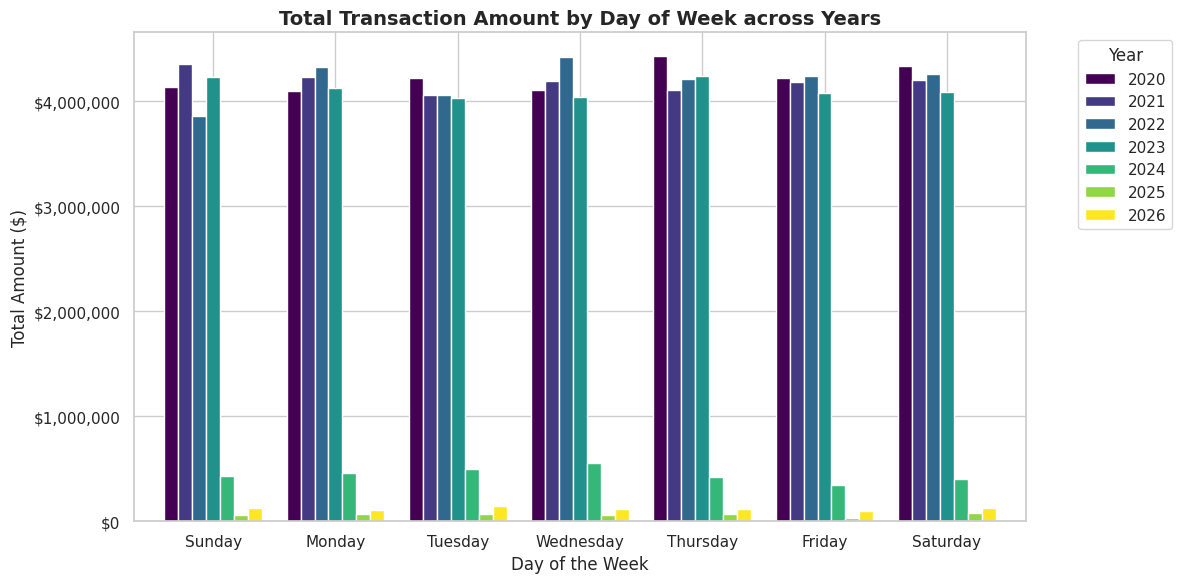

In [187]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual theme
sns.set_theme(style="whitegrid")

# Order To Follow within the Graph
days_order = ['Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday']

per_DOW['transaction_dow'] = pd.Categorical(
    per_DOW['transaction_dow'],
    categories=days_order,
    ordered=True
    )

per_DOW = per_DOW.sort_values(by=['transaction_year', 'transaction_dow'])


# Pivot the data so years can be compared easily across days of the week
dow_pivot = per_DOW.pivot(index='transaction_dow', columns='transaction_year', values='total_amount')

# Plotting a multi-year Day-of-Week comparison bar chart
fig, ax = plt.subplots(figsize=(12, 6))
dow_pivot.plot(kind='bar', ax=ax, colormap='viridis', width=0.8)

plt.title('Total Transaction Amount by Day of Week across Years', fontsize=14, fontweight='bold')
plt.xlabel('Day of the Week', fontsize=12)
plt.ylabel('Total Amount ($)', fontsize=12)
plt.legend(title='Year', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.gca().yaxis.set_major_formatter('${x:,.0f}')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()



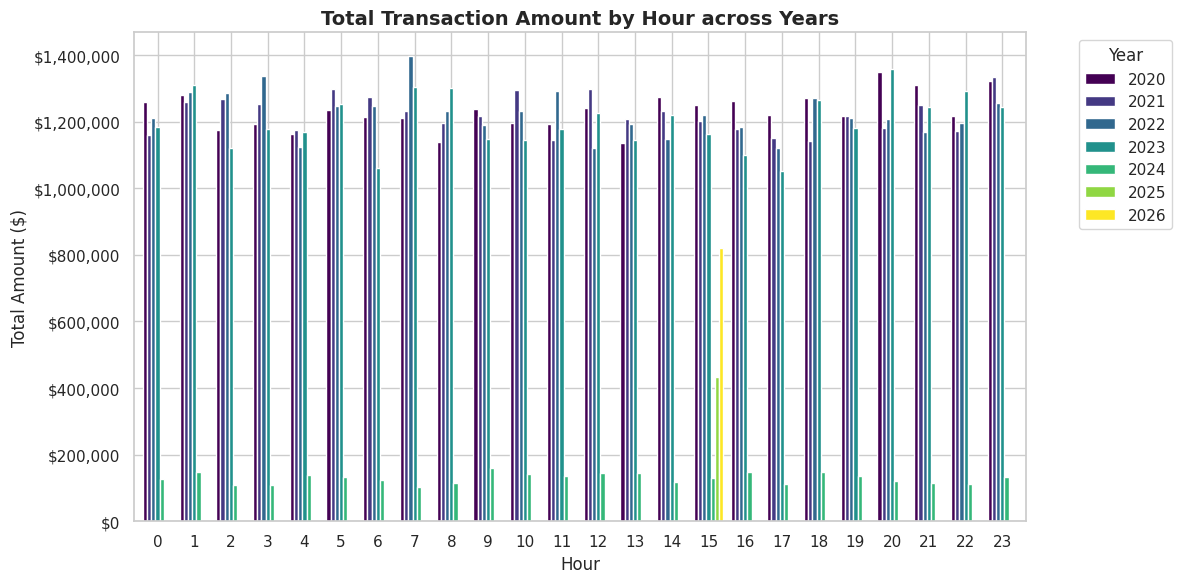

In [196]:
# Set visual theme
sns.set_theme(style="whitegrid")

# Pivot the data so years can be compared easily across days of the week
hour_pivot = per_hour.pivot(index='transaction_hour', columns='transaction_year', values='total_amount')

# Plotting a multi-year Day-of-Week comparison bar chart
fig, ax = plt.subplots(figsize=(12, 6))
hour_pivot.plot(kind='bar', ax=ax, colormap='viridis', width=0.8)

plt.title('Total Transaction Amount by Hour across Years', fontsize=14, fontweight='bold')
plt.xlabel('Hour', fontsize=12)
plt.ylabel('Total Amount ($)', fontsize=12)
plt.legend(title='Year', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.gca().yaxis.set_major_formatter('${x:,.0f}')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


In [203]:
# Customer Segment & Branch Performance Analysis

# Per Customer Type
per_customer_type = clean_df_transactions.groupby('Customer_Type').agg(
    total_transactions=('TransactionID', 'nunique'),
    total_amount=('Amount', 'sum'),
    avg_amount=('Amount', 'mean'),
    total_accounts=('AccountID', 'nunique'),
    total_customers=('CustomerID', 'nunique')
).reset_index()

# Calculate percentage contribution
total_amount = clean_df_transactions['Amount'].sum()
per_customer_type['amount_contribution_per_cs_type'] = (per_customer_type['total_amount'] / total_amount) * 100

print("Portfolio Performance Per Customer Type")
display(per_customer_type)

# Per Branch (Top 10 Branches by Volume)
per_branch = clean_df_transactions.groupby('BranchName').agg(
    total_transactions=('TransactionID', 'nunique'),
    total_amount=('Amount', 'sum'),
    avg_amount=('Amount', 'mean'),
    total_accounts=('AccountID', 'nunique'),
    total_customers=('CustomerID', 'nunique')
).reset_index()

per_branch = per_branch.sort_values(by='total_amount', ascending=False)

print("Top 10 Branches By Transaction Amount")
display(per_branch.head(10))

Portfolio Performance Per Customer Type


,Customer_Type,total_transactions,total_amount,avg_amount,total_accounts,total_customers,amount_contribution_per_cs_type
0,Individual,14835,37011831.78,2494.899345,504,272,30.466596
1,Large Enterprise,18095,45232991.73,2499.750855,619,324,37.233912
2,Small Business,15580,39238495.15,2518.517019,528,266,32.299492


Top 10 Branches By Transaction Amount


,BranchName,total_transactions,total_amount,avg_amount,total_accounts,total_customers
41,Branch 47,1019,2621315.78,2572.439431,768,561
49,Branch 9,1001,2564076.96,2561.515445,743,558
40,Branch 46,1026,2556958.68,2492.162456,759,546
32,Branch 39,985,2551750.29,2590.609431,739,532
38,Branch 44,1012,2540291.48,2510.169447,752,553
45,Branch 50,1034,2535970.27,2452.582466,765,554
46,Branch 6,1005,2533052.21,2520.449960,739,529
16,Branch 24,982,2527263.95,2573.588544,735,534
17,Branch 25,1002,2520863.28,2515.831617,755,547
19,Branch 27,1015,2516521.36,2479.331389,771,565


In [42]:
clean_df_transactions

,TransactionID,AccountOriginID,AccountDestinationID,TransactionTypeID,Amount,TransactionDate,BranchID,Description,Transaction_Type,BranchName,AddressID_tr,AccountID,CustomerID,AccountTypeID,AccountStatusID,Balance,OpeningDate,Account_Type,StatusName,FirstName,LastName,DateOfBirth,AddressID_cst,CustomerTypeID,Customer_Type,AddressID,Street,City,Country,age,transaction_year,transaction_hour,transaction_month,transaction_dow
0,3022681,201164,200868,2,855.17,2023-04-20 02:00:00,41,Transaction 22681,Withdrawal,Branch 41,173,201164,10426,3,1,55889.89,2018-11-14,Payroll,Active,Damion,Compton,1991-07-27,1190,1,Individual,1190,East,Tinley Park,United States,35.0,2023,2,2023-04,Thursday
1,3037846,200138,201402,2,806.20,2021-08-10 15:00:00,43,Transaction 37846,Withdrawal,Branch 43,742,200138,10735,1,3,35239.90,2019-03-04,Checking,Closed,Jonas,Santiago,1996-01-06,1015,3,Large Enterprise,1015,Felton,Camas,United States,31.0,2021,15,2021-08,Tuesday
2,3045293,201002,201180,1,1229.44,2020-08-16 03:00:00,5,Transaction 45293,Deposit,Branch 5,796,201002,10458,3,1,92795.90,2020-09-20,Payroll,Active,Belkis,Trevino,1994-05-13,832,2,Small Business,832,Waller,Mount Pleasant,United States,32.0,2020,3,2020-08,Sunday
3,3017397,201066,201144,4,4441.60,2021-10-10 06:00:00,14,Transaction 17397,Payment,Branch 14,491,201066,10557,1,1,48854.26,2020-12-30,Checking,Active,Loyd,Baird,1963-02-04,47,2,Small Business,47,Thomas,Walnut,United States,64.0,2021,6,2021-10,Sunday
4,3016750,200289,201413,3,2526.20,2022-07-28 00:00:00,37,Transaction 16750,Transfer,Branch 37,265,200289,10699,4,1,59032.48,2018-11-13,Business,Active,Claudio,Unknown,1983-10-15,614,2,Small Business,614,Rodriguez,Rocklin,United States,43.0,2022,0,2022-07,Thursday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
53646,3030796,200162,200716,2,518.49,2021-10-13 06:00:00,41,Transaction 30796,Withdrawal,Branch 41,173,200162,10504,5,1,13680.97,2018-04-19,Youth,Active,Victor,Barry,1960-03-14,928,1,Individual,928,Saroyan,Grayslake,United States,67.0,2021,6,2021-10,Wednesday
53647,3028048,200640,201374,2,2486.96,2023-11-04 23:00:00,2,Transaction 28048,Withdrawal,Branch 2,511,200640,10570,2,1,41593.86,2019-01-12,Savings,Active,Michale,Duffy,1966-09-11,683,1,Individual,683,Battery Blaney,Louisville,United States,60.0,2023,23,2023-11,Saturday
53648,3006284,200709,200667,4,3978.09,2022-06-03 02:00:00,11,Transaction 6284,Payment,Branch 11,30,200709,10335,1,1,60544.65,2019-06-16,Checking,Active,Brandon,Mayo,1963-10-14,381,2,Small Business,381,Sunset,Trussville,United States,63.0,2022,2,2022-06,Friday
53649,3028219,200513,200603,1,1507.27,2021-11-18 12:00:00,3,Transaction 28219,Deposit,Branch 3,27,200513,10997,3,2,76110.76,2020-08-31,Payroll,Inactive,Mila,Espinoza,1961-05-05,206,3,Large Enterprise,206,Wiese,Mount Pleasant,United States,66.0,2021,12,2021-11,Thursday
